# Exploratory Data Analysis: Superstore Retail Sales
**Datheon Data Analytics & Power BI Internship, Task 1**

**Objective:** Clean the Superstore sales data, profile missing values, and uncover insights on customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity.

**Tools:** Python, Pandas, Matplotlib, Seaborn

**Notebook flow:** Load → Inspect → Clean → Feature engineering → Analyse → Business findings

## 1. Setup

In [92]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

os.makedirs("figures", exist_ok=True)          # charts get saved here for your README

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

money = mtick.StrMethodFormatter("${x:,.0f}")

## 2. Load the data

In [122]:
# encoding="latin1" avoids UnicodeDecodeError on some special characters in this file
raw = pd.read_csv("superstore_sales.csv", encoding="latin1")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 3. Initial inspection
The file reports about 10,800 rows, but the Superstore dataset normally has **9,994 orders**. Let's see what the extra rows are.

In [123]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

In [124]:
# Rows where Order Date is empty are suspicious
extra = raw[raw["Order Date"].isnull()]
print("Rows with no Order Date:", len(extra))
extra.iloc[:, :2].head(12)

Rows with no Order Date: 806


,Row ID,Order ID
9994,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South
9999,Returned,Order ID
10000,Yes,CA-2015-100762
10001,Yes,CA-2015-100762
10002,Yes,CA-2015-100762
10003,Yes,CA-2015-100762


In [125]:
print(extra["Row ID"].value_counts().head(8))

Row ID
Yes                  800
Person                 1
Anna Andreadi          1
Chuck Magee            1
Kelly Williams         1
Cassandra Brandow      1
Returned               1
Name: count, dtype: int64


**Observation:** The last ~806 rows are not sales records. They are two small lookup tables pasted below the data (the original workbook's other sheets):
- A **regional manager table** (`Person` / `Region`), 4 rows plus header.
- A **returns table** (`Returned` = Yes, with an `Order ID`), 800 rows plus header.

I separate them instead of deleting blindly. The returns list is useful, so I keep it as a flag.

## 4. Data cleaning

### 4.1 Separate sales records from the pasted lookup tables

In [126]:
# Returned order IDs (from the lookup table pasted at the bottom)
returned_ids = set(extra.loc[extra["Row ID"] == "Yes", "Order ID"])
print("Distinct returned orders:", len(returned_ids))

# Regional managers (small lookup table)
managers = extra[extra["Order ID"].isin(["West", "East", "Central", "South"])].iloc[:, :2]
managers.columns = ["Manager", "Region"]
print(managers.to_string(index=False))

# The actual sales data
df = raw.dropna(subset=["Order Date"]).copy()
print("\nClean sales rows:", df.shape)

Distinct returned orders: 296
          Manager  Region
    Anna Andreadi    West
      Chuck Magee    East
   Kelly Williams Central
Cassandra Brandow   South

Clean sales rows: (9994, 21)


### 4.2 Missing-value profiling

In [127]:
missing = pd.DataFrame({
    "missing": df.isnull().sum(),
    "pct": (df.isnull().mean() * 100).round(2),
})
missing[missing["missing"] > 0]

,missing,pct
Postal Code,11,0.11


In [131]:
df[df["Postal Code"].isnull()][["City", "State", "Postal Code"]].drop_duplicates()

,City,State,Postal Code


Only **Postal Code** has gaps, and all of them are for one city: **Burlington, Vermont**. I fill them with Burlington's postal code (05401). The code is not used for any calculation, so this has no effect on the analysis, but it keeps the column complete.

In [132]:
df["Postal Code"] = df["Postal Code"].fillna(5401)
# Postal codes are identifiers, not numbers: store as 5-character text (restores leading zeros)
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### 4.3 Fix data types

In [133]:
df["Row ID"]   = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)

# Dates are in month/day/year format
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")

df.dtypes

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code              object
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

### 4.4 Duplicates and sanity checks

In [134]:
print("Duplicate rows            :", df.duplicated().sum())
print("Duplicate Row IDs         :", df["Row ID"].duplicated().sum())
print("Ship date before order    :", (df["Ship Date"] < df["Order Date"]).sum())
print("Sales <= 0                :", (df["Sales"] <= 0).sum())
print("Quantity <= 0             :", (df["Quantity"] <= 0).sum())
print("Discount outside 0-100%   :", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())
print("Date range                :", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

Duplicate rows            : 0
Duplicate Row IDs         : 0
Ship date before order    : 0
Sales <= 0                : 0
Quantity <= 0             : 0
Discount outside 0-100%   : 0
Date range                : 2015-01-03 to 2018-12-30


The data passes all checks: no duplicates, valid dates, positive sales and quantities, and discounts within range.

### 4.5 Feature engineering

In [135]:
df["Year"]       = df["Order Date"].dt.year
df["Month"]      = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["Year-Month"] = df["Order Date"].dt.to_period("M")
df["Ship Days"]  = (df["Ship Date"] - df["Order Date"]).dt.days
df["Returned"]   = df["Order ID"].isin(returned_ids)
df["Profit Margin %"] = df["Profit"] / df["Sales"] * 100

# Discount bands for the sensitivity analysis
bins   = [-0.001, 0, 0.2, 0.4, 0.6, 0.8]
labels = ["0% (none)", "1-20%", "21-40%", "41-60%", "61-80%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

df.to_csv("superstore_cleaned.csv", index=False)
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Discount,Profit,Year,Month,Month Name,Year-Month,Ship Days,Returned,Profit Margin %,Discount Band
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0.00,41.9136,2017,11,Nov,2017-11,3,False,16.00,0% (none)
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0.00,219.5820,2017,11,Nov,2017-11,3,False,30.00,0% (none)
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,0.00,6.8714,2017,6,Jun,2017-06,4,False,47.00,0% (none)
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0.45,-383.0310,2016,10,Oct,2016-10,7,False,-40.00,41-60%
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0.20,2.5164,2016,10,Oct,2016-10,7,False,11.25,1-20%


## 5. Overview

In [136]:
total_sales  = df["Sales"].sum()
total_profit = df["Profit"].sum()
print(f"Orders           : {df['Order ID'].nunique():,}")
print(f"Order lines      : {len(df):,}")
print(f"Customers        : {df['Customer ID'].nunique():,}")
print(f"Total sales      : ${total_sales:,.0f}")
print(f"Total profit     : ${total_profit:,.0f}")
print(f"Overall margin   : {total_profit / total_sales:.1%}")
print(f"Loss-making lines: {(df['Profit'] < 0).mean():.1%}")
df[["Sales", "Quantity", "Discount", "Profit"]].describe().round(2)

Orders           : 5,009
Order lines      : 9,994
Customers        : 793
Total sales      : $2,297,201
Total profit     : $286,397
Overall margin   : 12.5%
Loss-making lines: 18.7%


,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


## 6. Sales trend and monthly seasonality

In [137]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Margin %"] = (yearly["Profit"] / yearly["Sales"] * 100).round(1)
yearly["Sales Growth %"] = (yearly["Sales"].pct_change() * 100).round(1)
yearly.round(0)

,Sales,Profit,Margin %,Sales Growth %
Year,,,,
2015,484247.0,49544.0,10.0,NaN
2016,470533.0,61619.0,13.0,-3.0
2017,609206.0,81795.0,13.0,30.0
2018,733215.0,93439.0,13.0,20.0


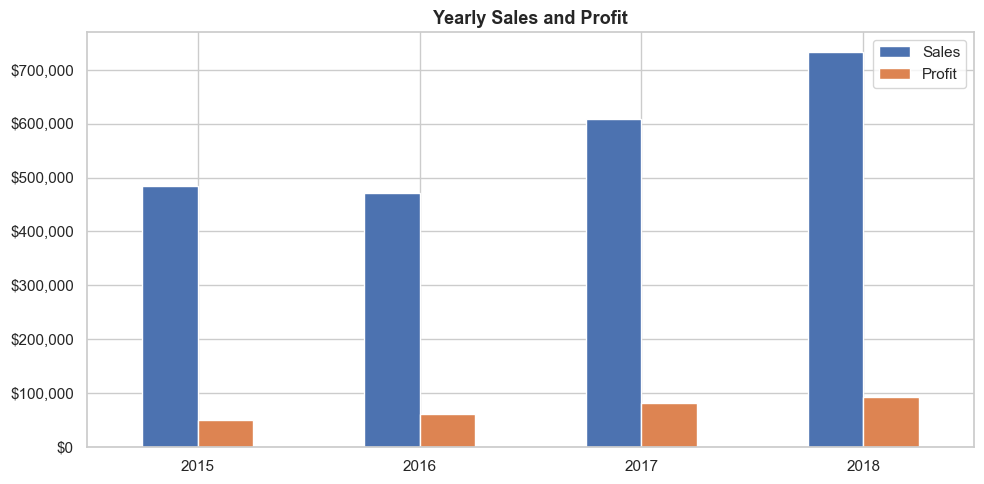

In [106]:
fig, ax = plt.subplots()
yearly[["Sales", "Profit"]].plot(kind="bar", ax=ax)
ax.yaxis.set_major_formatter(money)
ax.set_title("Yearly Sales and Profit")
ax.set_xlabel("")
plt.xticks(rotation=0)
save("01_yearly_sales_profit")

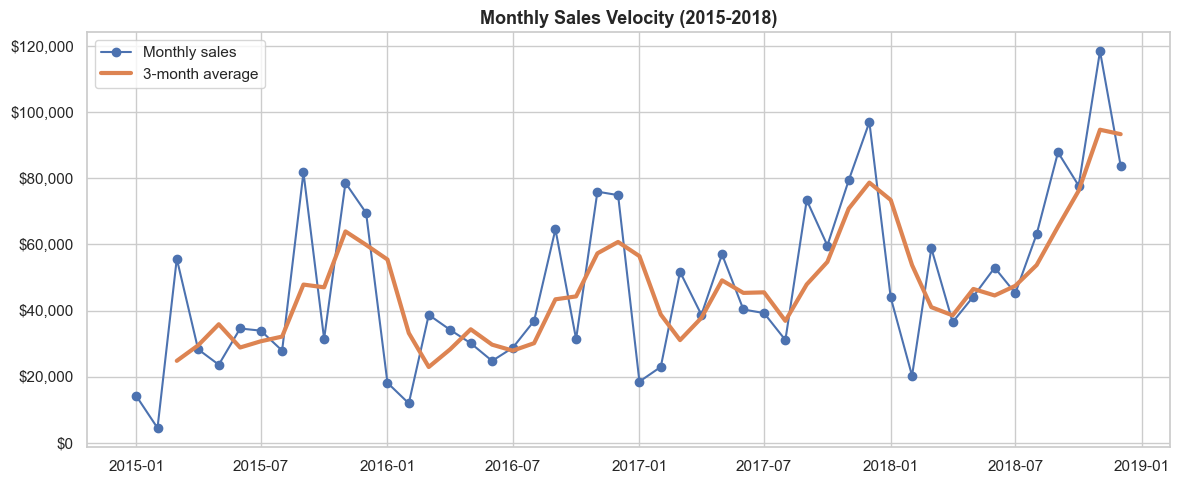

In [138]:
monthly = df.groupby("Year-Month")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly.values, marker="o", label="Monthly sales")
ax.plot(monthly.index, monthly.rolling(3).mean(), linewidth=3, label="3-month average")
ax.yaxis.set_major_formatter(money)
ax.set_title("Monthly Sales Velocity (2015-2018)")
ax.legend()
save("02_monthly_sales_velocity")

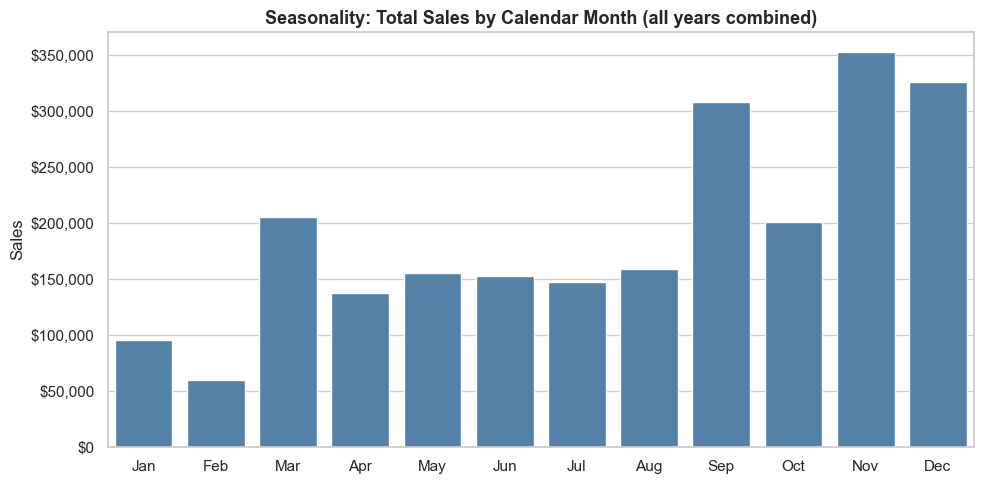

Nov + Dec share of all sales: 29.5%


In [139]:
season = df.groupby(["Month", "Month Name"])["Sales"].sum().reset_index().sort_values("Month")

fig, ax = plt.subplots()
sns.barplot(data=season, x="Month Name", y="Sales", color="steelblue", ax=ax)
ax.yaxis.set_major_formatter(money)
ax.set_title("Seasonality: Total Sales by Calendar Month (all years combined)")
ax.set_xlabel("")
save("03_monthly_seasonality")

q4_share = season[season["Month"].isin([11, 12])]["Sales"].sum() / season["Sales"].sum()
print(f"Nov + Dec share of all sales: {q4_share:.1%}")

## 7. Category-wise revenue and profit

In [140]:
cat = df.groupby("Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                 Orders=("Order ID", "nunique"))
cat["Margin %"] = (cat["Profit"] / cat["Sales"] * 100).round(1)
cat.sort_values("Sales", ascending=False).round(0)

,Sales,Profit,Orders,Margin %
Category,,,,
Technology,836154.0,145455.0,1544,17.0
Furniture,742000.0,18451.0,1764,2.0
Office Supplies,719047.0,122491.0,3742,17.0


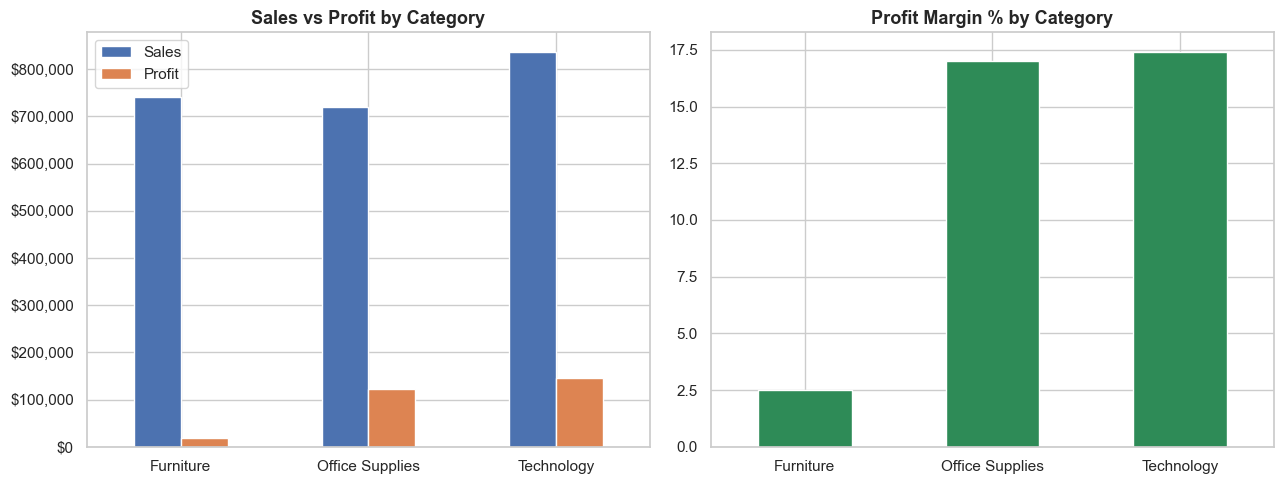

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cat[["Sales", "Profit"]].plot(kind="bar", ax=axes[0])
axes[0].yaxis.set_major_formatter(money)
axes[0].set_title("Sales vs Profit by Category")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

cat["Margin %"].plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Profit Margin % by Category")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
save("04_category_performance")

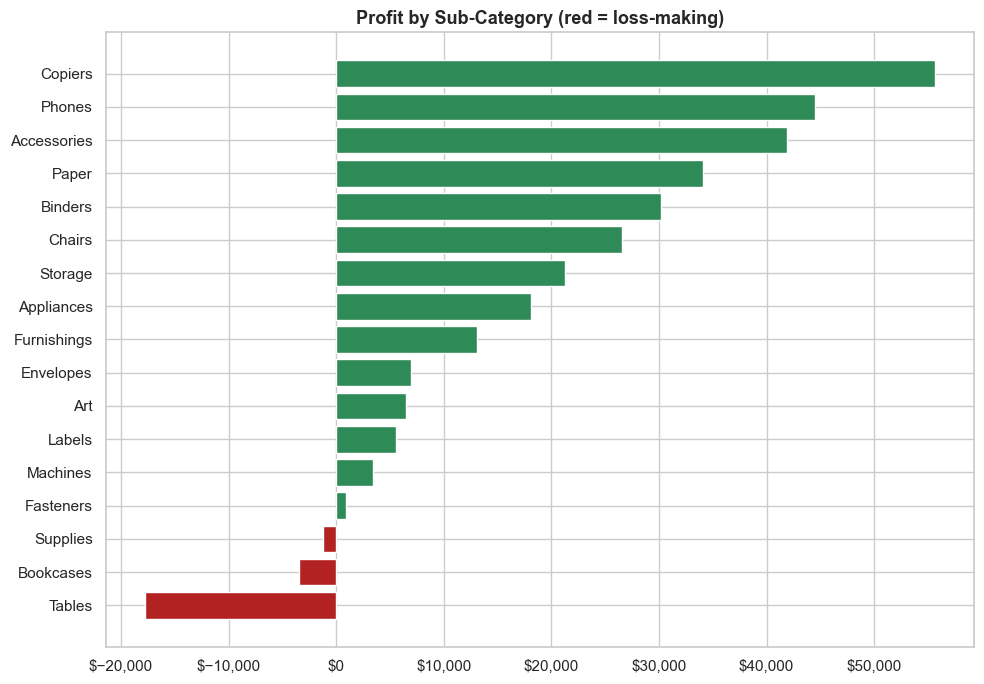

,Sales,Profit
Sub-Category,,
Tables,206966.0,-17725.0
Bookcases,114880.0,-3473.0
Supplies,46674.0,-1189.0


In [141]:
sub = df.groupby("Sub-Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Profit")

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["firebrick" if p < 0 else "seagreen" for p in sub["Profit"]]
ax.barh(sub.index, sub["Profit"], color=colors)
ax.xaxis.set_major_formatter(money)
ax.set_title("Profit by Sub-Category (red = loss-making)")
save("05_subcategory_profit")

sub[sub["Profit"] < 0].round(0)

## 8. Region and customer segment

In [142]:
region = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
region["Margin %"] = (region["Profit"] / region["Sales"] * 100).round(1)
segment = df.groupby("Segment").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
segment["Margin %"] = (segment["Profit"] / segment["Sales"] * 100).round(1)
display(region.sort_values("Sales", ascending=False).round(0))
display(segment.sort_values("Sales", ascending=False).round(0))

,Sales,Profit,Margin %
Region,,,
West,725458.0,108418.0,15.0
East,678781.0,91523.0,14.0
Central,501240.0,39706.0,8.0
South,391722.0,46749.0,12.0


,Sales,Profit,Margin %
Segment,,,
Consumer,1161401.0,134119.0,12.0
Corporate,706146.0,91979.0,13.0
Home Office,429653.0,60299.0,14.0


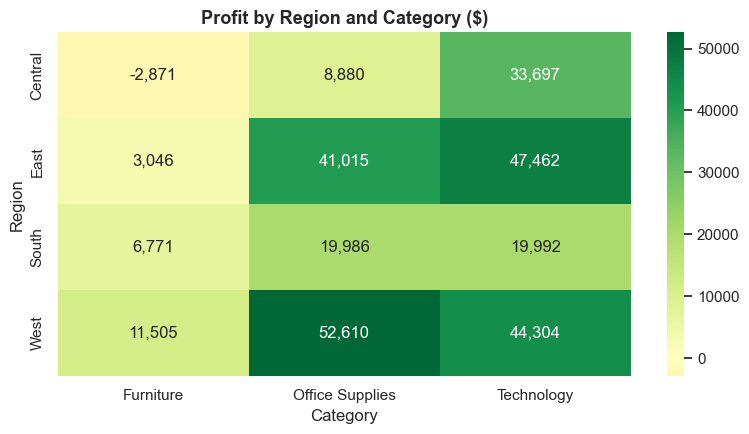

In [113]:
pivot = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=ax)
ax.set_title("Profit by Region and Category ($)")
save("06_region_category_heatmap")

In [144]:
state_profit = df.groupby("State")["Profit"].sum().sort_values()
print("Five least profitable states:")
print(state_profit.head(5).round(0))

Five least profitable states:
State
Texas            -25729.0
Ohio             -16971.0
Pennsylvania     -15560.0
Illinois         -12608.0
North Carolina    -7491.0
Name: Profit, dtype: float64


## 9. Discount sensitivity

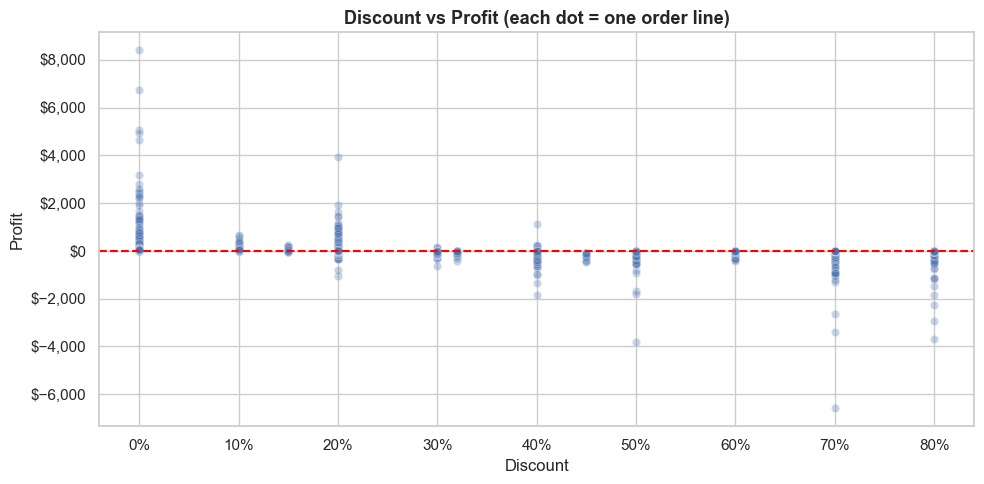

In [145]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.3, ax=ax)
ax.axhline(0, color="red", linestyle="--")
ax.yaxis.set_major_formatter(money)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Discount vs Profit (each dot = one order line)")
save("07_discount_vs_profit_scatter")

In [146]:
disc = df.groupby("Discount Band").agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
disc["Margin %"] = (disc["Profit"] / disc["Sales"] * 100).round(1)
disc.round(0)

,Lines,Sales,Profit,Margin %
Discount Band,,,,
0% (none),4798,1087908.0,320988.0,30.0
1-20%,3803,846522.0,100785.0,12.0
21-40%,460,234138.0,-35817.0,-15.0
41-60%,215,71048.0,-28944.0,-41.0
61-80%,718,57584.0,-70614.0,-123.0


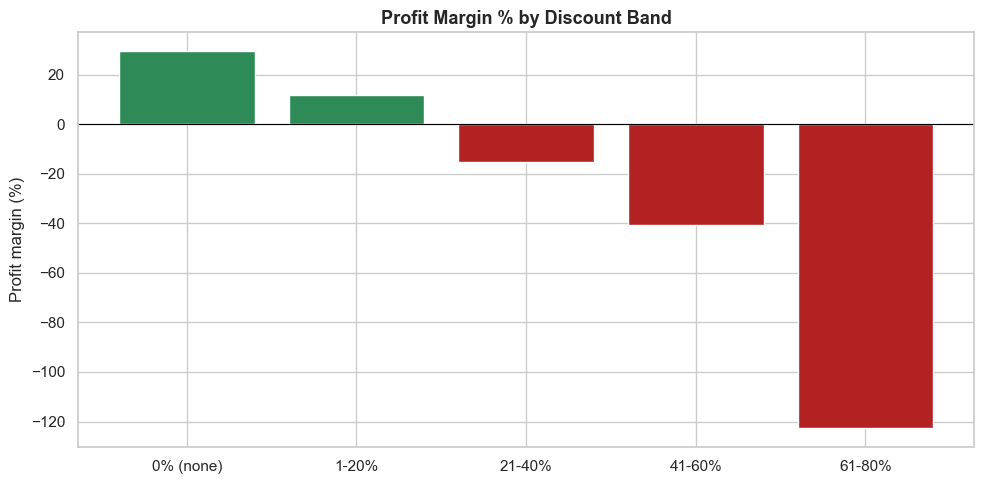

Corr(Discount, Profit): -0.219
Total profit on lines discounted above 20%: $-135,376


In [147]:
fig, ax = plt.subplots()
colors = ["seagreen" if m > 0 else "firebrick" for m in disc["Margin %"]]
ax.bar(disc.index.astype(str), disc["Margin %"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profit Margin % by Discount Band")
ax.set_ylabel("Profit margin (%)")
ax.set_xlabel("")
save("08_discount_band_margin")

print("Corr(Discount, Profit):", round(df["Discount"].corr(df["Profit"]), 3))
loss_over_20 = df[df["Discount"] > 0.2]["Profit"].sum()
print(f"Total profit on lines discounted above 20%: ${loss_over_20:,.0f}")

## 10. Customer purchase volume

In [149]:
cust = df.groupby(["Customer ID", "Customer Name"]).agg(
    Orders=("Order ID", "nunique"), Sales=("Sales", "sum"), Profit=("Profit", "sum")
).reset_index()

print("Customers:", len(cust))
print("Average orders per customer:", round(cust["Orders"].mean(), 1))
print("Top 10 customers' share of sales:", f"{cust.nlargest(10, 'Sales')['Sales'].sum() / cust['Sales'].sum():.1%}")
cust.nlargest(10, "Sales").round(0)

Customers: 793
Average orders per customer: 6.3
Top 10 customers' share of sales: 6.7%


,Customer ID,Customer Name,Orders,Sales,Profit
700,SM-20320,Sean Miller,5,25043.0,-1981.0
741,TC-20980,Tamara Chand,5,19052.0,8981.0
621,RB-19360,Raymond Buch,6,15117.0,6976.0
730,TA-21385,Tom Ashbrook,4,14596.0,4704.0
6,AB-10105,Adrian Barton,10,14474.0,5445.0
434,KL-16645,Ken Lonsdale,12,14175.0,807.0
669,SC-20095,Sanjit Chand,9,14142.0,5757.0
327,HL-15040,Hunter Lopez,6,12873.0,5622.0
683,SE-20110,Sanjit Engle,11,12209.0,2651.0
131,CC-12370,Christopher Conant,5,12129.0,2177.0


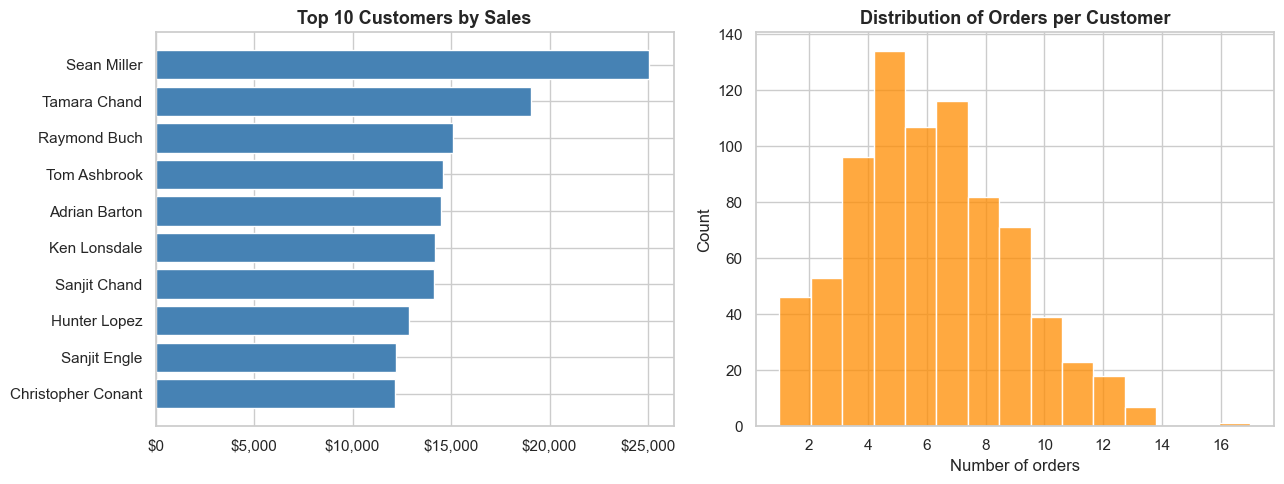

In [150]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top10 = cust.nlargest(10, "Sales").sort_values("Sales")
axes[0].barh(top10["Customer Name"], top10["Sales"], color="steelblue")
axes[0].xaxis.set_major_formatter(money)
axes[0].set_title("Top 10 Customers by Sales")

sns.histplot(cust["Orders"], bins=15, ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of Orders per Customer")
axes[1].set_xlabel("Number of orders")
save("09_customer_volume")

## 11. Returns and shipping (bonus)

In [153]:
order_level = df.groupby("Order ID").agg(Returned=("Returned", "max"))
print(f"Return rate (orders): {order_level['Returned'].mean():.1%}")

ret_cat = df.groupby("Category")["Returned"].mean().mul(100).round(1)
print("\nReturned share of order lines by category (%):")
print(ret_cat)

print("\nAverage days to ship by ship mode:")
print(df.groupby("Ship Mode")["Ship Days"].mean().round(1))

Return rate (orders): 5.9%

Returned share of order lines by category (%):
Category
Furniture          8.1
Office Supplies    7.8
Technology         8.4
Name: Returned, dtype: float64

Average days to ship by ship mode:
Ship Mode
First Class       2.2
Same Day          0.0
Second Class      3.2
Standard Class    5.0
Name: Ship Days, dtype: float64


## 12. Correlation check

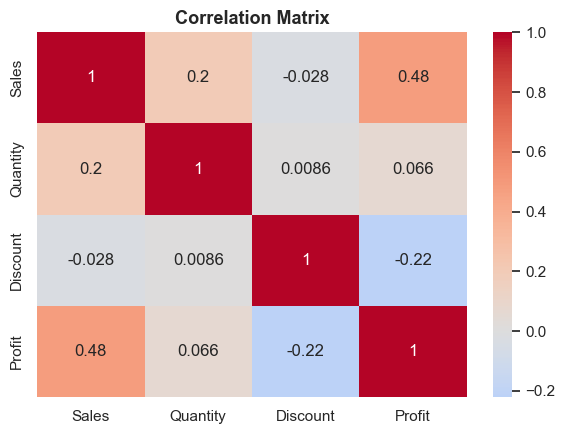

In [154]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(df[["Sales", "Quantity", "Discount", "Profit"]].corr(), annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix")
save("10_correlation")

## 13. Executive takeaways

> Numbers below come from this dataset. If anything you see in your own output differs slightly, trust your output and edit the text.

**1. Sales are growing, and margin is improving.**
Sales rose from about **$484K in 2015 to $733K in 2018 (+51%)**, with a small dip in 2016. Profit nearly doubled (about $49.5K to $93.4K), and margin moved from roughly 10% to 13%. The business is growing and getting more efficient.

**2. Sales are strongly seasonal.**
**September, November and December** are the peak months. November and December alone bring in about **30% of annual sales**, while January and February are the weakest months. *Recommendation:* build inventory and marketing capacity ahead of September, and use promotions to lift the slow first quarter.

**3. Furniture sells a lot but earns almost nothing.**
Furniture generates about **$742K in sales but only about $18K profit (about 2.5% margin)**. Technology (about $145K profit) and Office Supplies (about $122K) are far more profitable. *Recommendation:* review Furniture pricing and costs before pushing more volume.

**4. Heavy discounting destroys profit.**
Items sold at no discount earn a **29.5% margin**, and 1-20% discounts still earn about 12%. Above 20%, margins turn negative: **-15% (21-40%), -41% (41-60%) and -123% (61-80%)**. Lines discounted above 20% lost a combined **$135K**. *Recommendation:* cap discounts at around 20% and require approval beyond that.

**5. A few sub-categories lose money.**
**Tables (about -$17.7K), Bookcases (about -$3.5K) and Supplies (about -$1.2K)** are loss-making overall. Tables alone bring in about $207K in sales, so this is not a small-volume problem. Texas, Ohio and Pennsylvania are the least profitable states, which is worth checking against their discount levels.

**6. Regional performance is uneven.**
West and East lead in sales and profit. **Central has the weakest margin (about 8%)** compared with West (about 15%), despite similar product mix, which points to pricing or discounting differences.

**7. The customer base is broad, not concentrated.**
There are 793 customers who place about **6 orders each on average**, and the top 10 customers account for only **about 7% of sales**. Revenue does not depend on a few accounts, so the focus should be on repeat purchases and order value rather than protecting a handful of key accounts.

**8. Returns are modest and not tied to one category.**
About **6% of orders (296 of 5,009) were returned**, and the returned share of order lines is similar across Furniture, Office Supplies and Technology (roughly 8% each). Returns are a general cost to monitor rather than a category-specific problem.

## 14. Next steps
- Use `superstore_cleaned.csv` as the source for the **Task 2 Power BI dashboard**.
- Investigate why Central and the loss-making states underperform (discount levels, product mix).
- Test whether capping discounts at 20% would have improved overall profit.